In [2]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:4 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.3 kB]
Get:5 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [1,919 kB]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:7 http://archive.ubuntu.com/ubuntu noble InRelease
Get:8 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:11 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:12 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.4 MB]
Get:13 http://security.ubuntu.com/ubuntu n

In [3]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Writing main.cpp


In [4]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [5]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Writing setup.sh


In [6]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


images_1 işleniyor...
images_2 işleniyor...


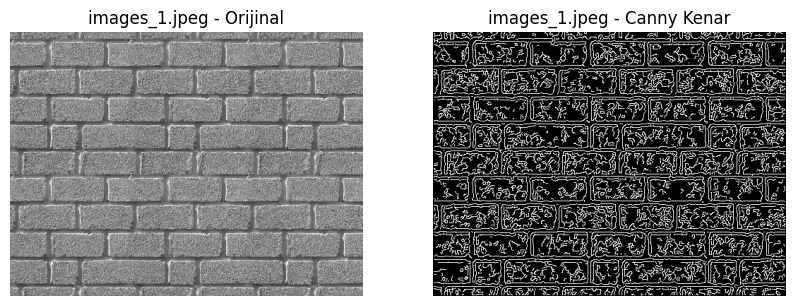

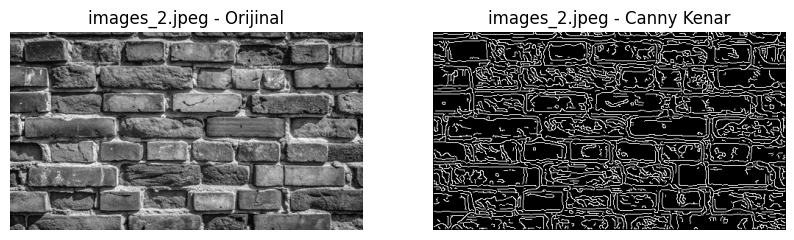

In [13]:
# Her iki resmi bağımsız işle
print("images_1 işleniyor...")
i1, e1 = canny_process("images_1.jpeg")

print("images_2 işleniyor...")
i2, e2 = canny_process("images_2.jpeg")

# 1. Resim ve Kenarları
if i1 is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(i1, cmap='gray')
    axes[0].set_title("images_1.jpeg - Orijinal")
    axes[0].axis('off')

    axes[1].imshow(e1, cmap='gray')
    axes[1].set_title("images_1.jpeg - Canny Kenar")
    axes[1].axis('off')
    plt.show()
else:
    print("UYARI: images_1.jpeg okunamadı! Sol paneldeki dosya adını kontrol edin.")

# 2. Resim ve Kenarları
if i2 is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(i2, cmap='gray')
    axes[0].set_title("images_2.jpeg - Orijinal")
    axes[0].axis('off')

    axes[1].imshow(e2, cmap='gray')
    axes[1].set_title("images_2.jpeg - Canny Kenar")
    axes[1].axis('off')
    plt.show()
else:
    print("UYARI: images_2.jpeg okunamadı! Sol paneldeki dosya adını kontrol edin.")